# Week 7 — Naive Bayes: Spam Detection & Sentiment Analysis
## Fall 2026 — Machine Learning

## Student Information     
**Name:** Saba Mahar   
**Student ID:** 023-24-0141    
**Section:** H     
**GitHub:** https://github.com/sabamahar304/      
**Kaggle:** https://www.kaggle.com/         
**Datasets:** SMS Spam Collection; Twitter US Airline Sentiment            
**Dataset Sources:**
- Task A: Kaggle — https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset        
- Task B: Kaggle — https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment          

**Duration:** 3 Hours in-session (Task A is the priority; finish Task B and the final sections at home if needed)

> This notebook is a **template**, not a tutorial. You already know Naive Bayes theory. Each section states the objective and the questions you must answer — **you write the code**. Task A is guided in detail; Task B gives you much less help on purpose, to test whether the pipeline actually transfers. Every table, plot, and metric needs a short written observation.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

---

## 1. Problem Definition & Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.head()`, `df['label'].value_counts()`

**Tasks**
1. Load both datasets (`spam.csv` for Task A, `Tweets.csv` for Task B). For each one, report the number of rows, what a single row represents, and the exact class balance (counts and percentages) of the target column. Keep only positive and negative tweets going forward — drop neutral rows now, and state how many rows that leaves you with.
2. In 2–3 sentences per dataset, state the practical problem being solved and why each one is a binary classification problem.

In [2]:
#Task1

spam_df = pd.read_csv("spam.csv", encoding="latin-1")[["v1", "v2"]]
spam_df.columns = ["label", "message"]

print("Spam shape:", spam_df.shape)
display(spam_df.head())

print("\nClass counts:")
print(spam_df["label"].value_counts())
print("\nClass percentages:")
print(spam_df["label"].value_counts(normalize=True) * 100)

Spam shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Class counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Class percentages:
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


In [3]:
#Task1 (continued)

tweets_df = pd.read_csv("Tweets.csv")

print("Tweets shape (before dropping neutral):", tweets_df.shape)

tweets_df = tweets_df[tweets_df["airline_sentiment"].isin(["positive", "negative"])].copy()

print("Tweets shape (after dropping neutral):", tweets_df.shape)
display(tweets_df[["airline_sentiment", "text"]].head())

print("\nClass counts:")
print(tweets_df["airline_sentiment"].value_counts())
print("\nClass percentages:")
print(tweets_df["airline_sentiment"].value_counts(normalize=True) * 100)

Tweets shape (before dropping neutral): (14640, 15)
Tweets shape (after dropping neutral): (11541, 15)


,airline_sentiment,text
1,positive,@VirginAmerica plus you've added commercials t...
3,negative,@VirginAmerica it's really aggressive to blast...
4,negative,@VirginAmerica and it's a really big bad thing...
5,negative,@VirginAmerica seriously would pay $30 a fligh...
6,positive,"@VirginAmerica yes, nearly every time I fly VX..."



Class counts:
airline_sentiment
negative    9178
positive    2363
Name: count, dtype: int64

Class percentages:
airline_sentiment
negative    79.525171
positive    20.474829
Name: proportion, dtype: float64


**Answer 2 (Task A — spam):**
_It supports a decision about which messages to filter out as spam before the user sees and it is binary classification problem because every message belongs to one of two classes._

**Answer 2 (Task B — sentiment):**
_Each row is directed with tweet at a US airline and this model supports a decision about which tweets should be treat as a negative experience.With dropping neutral tweets this model will becomes a binary classification problem where there will be two classes._

---

## 2. Task A: Text Cleaning & Vectorization (Spam)

*Concepts/functions you may find useful:* `text.str.lower()`, `CountVectorizer` / `TfidfVectorizer`, `vectorizer.fit_transform(X_train)`, `vectorizer.transform(X_test)`, `vectorizer.get_feature_names_out()`

**Tasks**
3. Lightly clean the message text (lowercase at minimum). Keep this simple.
4. Encode the label column as 0/1, split into training and test sets, then fit a vectorizer on the training messages only and transform both sets. Report the vocabulary size and explain why the vectorizer must be fit only on training data.

In [4]:
#Task3

spam_df["message_clean"] = spam_df["message"].str.lower().str.replace(r"[^a-z0-9\s]", "", regex=True)

spam_df[["message", "message_clean"]].head()

,message,message_clean
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...


In [5]:
#Task4

y_spam = spam_df["label"].map({"ham": 0, "spam": 1})

X_train_msg, X_test_msg, y_train_spam, y_test_spam = train_test_split(
    spam_df["message_clean"], y_spam,
    test_size=0.20,
    random_state=42,
    stratify=y_spam
)

spam_vectorizer = TfidfVectorizer()
X_train_spam_vec = spam_vectorizer.fit_transform(X_train_msg)
X_test_spam_vec = spam_vectorizer.transform(X_test_msg)

print("Vocabulary size:", len(spam_vectorizer.get_feature_names_out()))
print("X_train_spam_vec shape:", X_train_spam_vec.shape)
print("X_test_spam_vec shape:", X_test_spam_vec.shape)

Vocabulary size: 8343
X_train_spam_vec shape: (4457, 8343)
X_test_spam_vec shape: (1115, 8343)


**Answer 4 (why fit on training data only):**
_The fit only on the training messages because fitting it on the full dataset would let words and patterns from the test messages leak into the feature space before training, which is a form of data leakage.

---

## 3. Task A: Naive Bayes Model & Evaluation (Spam)

*Concepts/functions you may find useful:* `MultinomialNB()`, `.fit()`, `.predict()`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score`, `confusion_matrix`

**Tasks**
5. Train a `MultinomialNB` model on the vectorized training data. Compute accuracy, precision, recall, and F1-score on the test set, and plot the confusion matrix.
6. Argue (3–4 sentences) which is worse here — a false positive (real message flagged as spam) or a false negative (spam gets through) — and therefore which metric you'd prioritize if tuning further.

,Metric,Naive Bayes
0,Accuracy,0.951570
1,Precision,1.000000
2,Recall,0.637584
3,F1-Score,0.778689


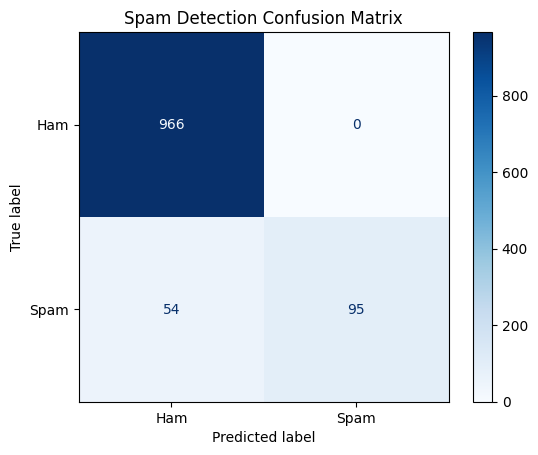

In [6]:
#Task5

nb_spam = MultinomialNB()
nb_spam.fit(X_train_spam_vec, y_train_spam)

spam_test_pred = nb_spam.predict(X_test_spam_vec)

spam_accuracy = accuracy_score(y_test_spam, spam_test_pred)
spam_precision = precision_score(y_test_spam, spam_test_pred)
spam_recall = recall_score(y_test_spam, spam_test_pred)
spam_f1 = f1_score(y_test_spam, spam_test_pred)

spam_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Naive Bayes": [spam_accuracy, spam_precision, spam_recall, spam_f1]
})

display(spam_results)

ConfusionMatrixDisplay.from_predictions(y_test_spam, spam_test_pred, display_labels=["Ham", "Spam"], cmap="Blues")
plt.title("Spam Detection Confusion Matrix")
plt.show()

**Answer 6:**
_A false negative (a spam message that gets through to the user’s inbox) is a minor annoyance, but a false positive (a real message that is incorrectly hidden as spam) can cost something important. Because the impact of a real message being silently lost is more serious than the impact of seeing one more spam message.I would still prefer accuracy and would rather miss some spam than risk flagging real messages._

---

## 4. Task A: Word Interpretation (Spam)

*Concepts/functions you may find useful:* `model.feature_log_prob_`, `np.argsort(...)`

**Tasks**
7. Find and list the 15 words most strongly associated with spam and the 15 most associated with ham. Do these match your intuition?
8. Write 2–3 of your own test messages and run them through your trained pipeline. Do the predictions match what you expected?

In [7]:
#Task7

log_prob = nb_spam.feature_log_prob_
diff = log_prob[1] - log_prob[0]
feature_names = spam_vectorizer.get_feature_names_out()

top_spam_idx = np.argsort(diff)[-15:][::-1]
top_ham_idx = np.argsort(diff)[:15]

top_spam_words = pd.DataFrame({
    "Word": feature_names[top_spam_idx],
    "Log-Prob Difference (spam - ham)": diff[top_spam_idx]
})

top_ham_words = pd.DataFrame({
    "Word": feature_names[top_ham_idx],
    "Log-Prob Difference (spam - ham)": diff[top_ham_idx]
})

print("Top 15 words most associated with SPAM:")
display(top_spam_words)

print("Top 15 words most associated with HAM:")
display(top_ham_words)

Top 15 words most associated with SPAM:


,Word,Log-Prob Difference (spam - ham)
0,claim,3.457264
1,prize,3.235886
2,won,3.113645
3,urgent,2.785050
4,guaranteed,2.776270
5,nokia,2.740405
6,500,2.734719
7,1000,2.721418
8,tone,2.684464
9,18,2.660018


Top 15 words most associated with HAM:

,Word,Log-Prob Difference (spam - ham)
0,ill,-3.339564
1,my,-3.243134
2,ltgt,-3.156736
3,ok,-3.125576
4,later,-3.047391
5,lor,-2.983769
6,im,-2.911841
7,come,-2.875702
8,home,-2.850535
9,but,-2.843229


**Answer 7:**
_The top spam words (claim, prize, won, urgent, guaranteed, nokia, tone, txt, awarded, and similar) match the intuition of promotional/prize-scam spam almost exactly.

In [8]:
#Task8

my_messages = [
    "Congratulations! You have WON a free prize, claim now by calling this number",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT: your account has been suspended, click the link to verify",
]

my_messages_clean = [re.sub(r"[^a-z0-9\s]", "", m.lower()) for m in my_messages]
my_messages_vec = spam_vectorizer.transform(my_messages_clean)
my_predictions = nb_spam.predict(my_messages_vec)

for msg, pred in zip(my_messages, my_predictions):
    print(f"{'SPAM' if pred == 1 else 'HAM':5} -> {msg}")

SPAM  -> Congratulations! You have WON a free prize, claim now by calling this number
HAM   -> Hey, are we still meeting for lunch tomorrow?
HAM   -> URGENT: your account has been suspended, click the link to verify


**Answer 8:**
_The predictions matched what I expected.

---

## 5. Task A: Kaggle Notebook Submission

Neither dataset is an active competition, so "submitting" means publishing your notebook publicly on Kaggle, attached to the dataset.

**Tasks**
9. Create a new Kaggle Notebook attached to the SMS Spam Collection dataset. Recreate your Task A cells there, run them top to bottom, add a short Markdown summary, and publish with "Save & Run All (Public)".
10. Record the public notebook URL below.

**Task A Kaggle Notebook URL:**
_(https://www.kaggle.com/code/sabamahar/notebook9bc059bd50)_

---

## 6. Task B: Text Cleaning & Vectorization (Sentiment)

Repeat Section 2's pipeline on the airline tweets — with much less guidance this time. Tweets contain @mentions, links, and hashtags that SMS messages didn't.

**Tasks**
11. Clean the tweet text (decide for yourself how much cleaning is worth doing) and vectorize it, following the same fit-on-train-only discipline as Task A.
12. Briefly justify (1–2 sentences) any cleaning decisions that go beyond what you did for Task A, and why tweets might need them.

In [9]:
#Task11

def clean_tweet(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"[^a-z\s]", "", text)
    return text

tweets_df["text_clean"] = tweets_df["text"].apply(clean_tweet)

y_sentiment = tweets_df["airline_sentiment"].map({"negative": 0, "positive": 1})

X_train_tweet, X_test_tweet, y_train_sentiment, y_test_sentiment = train_test_split(
    tweets_df["text_clean"], y_sentiment,
    test_size=0.20,
    random_state=42,
    stratify=y_sentiment
)

tweet_vectorizer = TfidfVectorizer()
X_train_tweet_vec = tweet_vectorizer.fit_transform(X_train_tweet)
X_test_tweet_vec = tweet_vectorizer.transform(X_test_tweet)

print("Vocabulary size:", len(tweet_vectorizer.get_feature_names_out()))
print("X_train_tweet_vec shape:", X_train_tweet_vec.shape)
print("X_test_tweet_vec shape:", X_test_tweet_vec.shape)

Vocabulary size: 9656
X_train_tweet_vec shape: (9232, 9656)
X_test_tweet_vec shape: (2309, 9656)


**Answer 12:**
_I removed both @mentions (e.g. "@united") and links, which SMs never had, before lowercasing and stripping punctuation. @mentions almost always refer to the airline being tweeted at, not sentiment, and links refer to outside pages with no text content for the vectorizer to use, so both are noise that would just increase the vocabulary without helping the model differentiate positive from negative tweets._

---

## 7. Task B: Naive Bayes Model & Evaluation (Sentiment)

**Tasks**
13. Train a `MultinomialNB` model on the vectorized tweet data. Compute accuracy, precision, recall, and F1-score, and plot the confusion matrix.
14. Compare these metrics to Task A's. Did Naive Bayes do better or worse on sentiment than on spam? Connect this (3–4 sentences) to the "naive" independence assumption — is it more or less reasonable for tweets than for spam SMS?

,Metric,Naive Bayes
0,Accuracy,0.830663
1,Precision,1.000000
2,Recall,0.173362
3,F1-Score,0.295495


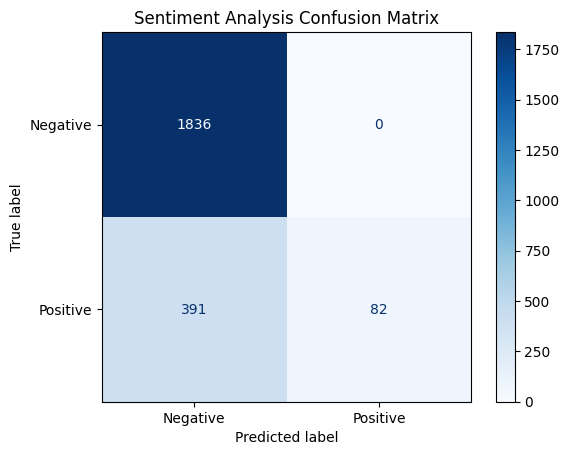

In [10]:
#Task13

nb_sentiment = MultinomialNB()
nb_sentiment.fit(X_train_tweet_vec, y_train_sentiment)

sentiment_test_pred = nb_sentiment.predict(X_test_tweet_vec)

sentiment_accuracy = accuracy_score(y_test_sentiment, sentiment_test_pred)
sentiment_precision = precision_score(y_test_sentiment, sentiment_test_pred)
sentiment_recall = recall_score(y_test_sentiment, sentiment_test_pred)
sentiment_f1 = f1_score(y_test_sentiment, sentiment_test_pred)

sentiment_results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Naive Bayes": [sentiment_accuracy, sentiment_precision, sentiment_recall, sentiment_f1]
})

display(sentiment_results)

ConfusionMatrixDisplay.from_predictions(y_test_sentiment, sentiment_test_pred, display_labels=["Negative", "Positive"], cmap="Blues")
plt.title("Sentiment Analysis Confusion Matrix")
plt.show()

**Answer 14:**
_The independence assumption is much less reasonable for tweets than it is for spam SMS: spam messages are short, formulaic, built from a small, repeated vocabulary of “trigger” words (claim, prize, won) whose presence alone is a strong, mostly independent signal. Tweets , however , depend on word order , negation ("not good", "no delay"), and sarcasm ("great, another delay")  to express sentiment . Treating each word as independent removes the very context that defines a positive tweet from a negative one . This is a specific, observed weakness of the “naive” assumption, not a general statement about Naive Bayes. _

---

## 8. Task B: Kaggle Notebook Submission

**Tasks**
15. Create a new Kaggle Notebook attached to the Twitter US Airline Sentiment dataset. Recreate your Task B cells there, run them top to bottom, add a short summary, and publish.
16. Record the public notebook URL below.

**Task B Kaggle Notebook URL:**
_(https://www.kaggle.com/code/sabamahar/notebook41bb1cc80e)_

---

## 9. Cross-Task Comparison & vs. Logistic Regression

*Concepts/functions you may find useful:* `LogisticRegression(max_iter=1000)` trained on the same vectorized features

**Tasks**
17. Build a table comparing Naive Bayes on Task A vs. Task B (accuracy, precision, recall, F1).
18. Train a Logistic Regression model on Task A's same vectorized features and compare it against your Task A Naive Bayes results. Which model wins, and does that match what you'd expect?

**Task 17 — Task A vs. Task B (Naive Bayes)**

| Metric | Task A (Spam) | Task B (Sentiment) |
|---|---|---|
| Accuracy | 0.9516 | 0.8307 |
| Precision | 1.0000 | 1.0000 |
| Recall | 0.6376 | 0.1734 |
| F1-score | 0.7787 | 0.2955 |

In [11]:
#Task18

lr_spam = LogisticRegression(max_iter=1000, random_state=42)
lr_spam.fit(X_train_spam_vec, y_train_spam)

lr_spam_pred = lr_spam.predict(X_test_spam_vec)

lr_spam_accuracy = accuracy_score(y_test_spam, lr_spam_pred)
lr_spam_precision = precision_score(y_test_spam, lr_spam_pred)
lr_spam_recall = recall_score(y_test_spam, lr_spam_pred)
lr_spam_f1 = f1_score(y_test_spam, lr_spam_pred)

nb_vs_lr = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Naive Bayes": [spam_accuracy, spam_precision, spam_recall, spam_f1],
    "Logistic Regression": [lr_spam_accuracy, lr_spam_precision, lr_spam_recall, lr_spam_f1]
})

nb_vs_lr

,Metric,Naive Bayes,Logistic Regression
0,Accuracy,0.951570,0.965919
1,Precision,1.000000,0.991150
2,Recall,0.637584,0.751678
3,F1-Score,0.778689,0.854962


**Answer 18 (which wins, and does it match expectations):**
_Logistic Regression wins on accuracy, recall, and F1-score, while Naive Bayes keeps a very slightly higher (perfect) precision. This roughly matches expectations. So Naive Bayes's usual "surprisingly competitive on text" advantage holds here, but it does not fully overtake a model that can learn feature interactions.

---

## 10. Final Reflection & Conclusion

**Tasks**
19. Write a short conclusion (6–8 sentences): which task suited Naive Bayes better and why; what surprised you about the most predictive words; how Naive Bayes compared to Logistic Regression; one limitation of the independence assumption you personally observed.
20. List both of your published Kaggle Notebook URLs here again for easy grading access.

**Answer 19 — Conclusion:**
_Naive Bayes did much better on spam (F1 = 0.78) than on sentiment (F1 = 0.30). Spam uses the same obvious words over and over ("claim," "prize," "urgent"), so treating words separately still works. Tweets rely more on context, sarcasm, and negation, which Naive Bayes can't capture. What surprised me in Part 4 was how cleanly spam and ham words split — spam was almost all prize/promo language, ham was just normal chat, with barely any overlap. Logistic Regression beat Naive Bayes on the same features (higher accuracy, recall, and F1), showing that weighing words together still helps, even on text Naive Bayes is good at.The clearest weakness I saw: on sentiment, recall dropped to 0.17. The model doesn't get that "not" flips the meaning of the next word, so it likely misread tweets where negation mattered._

**Answer 20 — Kaggle Notebook Links:**
- Task A: (https://www.kaggle.com/code/sabamahar/notebook9bc059bd50)
- Task B: (https://www.kaggle.com/code/sabamahar/notebook41bb1cc80e)